In [1]:
import pandas as pd

product_sales = pd.read_csv(
    r"D:\Portfolio\retail-online-analysis\data\product_sales.csv",
    dtype={'InvoiceNo': 'string'}
)

product_sales['InvoiceDate'] = pd.to_datetime(product_sales['InvoiceDate'])
product_sales['CustomerID'] = product_sales['CustomerID'].astype('Int64')

product_sales['Revenue'] = product_sales['Quantity'] * product_sales['UnitPrice']

In [2]:
# 1. Top 10 countries by revenue
top_countries_revenue = (
    product_sales.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
)
print("Top 10 Countries by Revenue:", top_countries_revenue.head(10))

Top 10 Countries by Revenue: Country
United Kingdom    8726000.344
Netherlands        283889.340
EIRE               276090.860
Germany            205381.150
France             184679.000
Australia          138103.810
Spain               55706.560
Switzerland         53065.600
Japan               37416.370
Belgium             36927.340
Name: Revenue, dtype: float64


In [3]:
top_10_countries_revenue = top_countries_revenue.head(10)

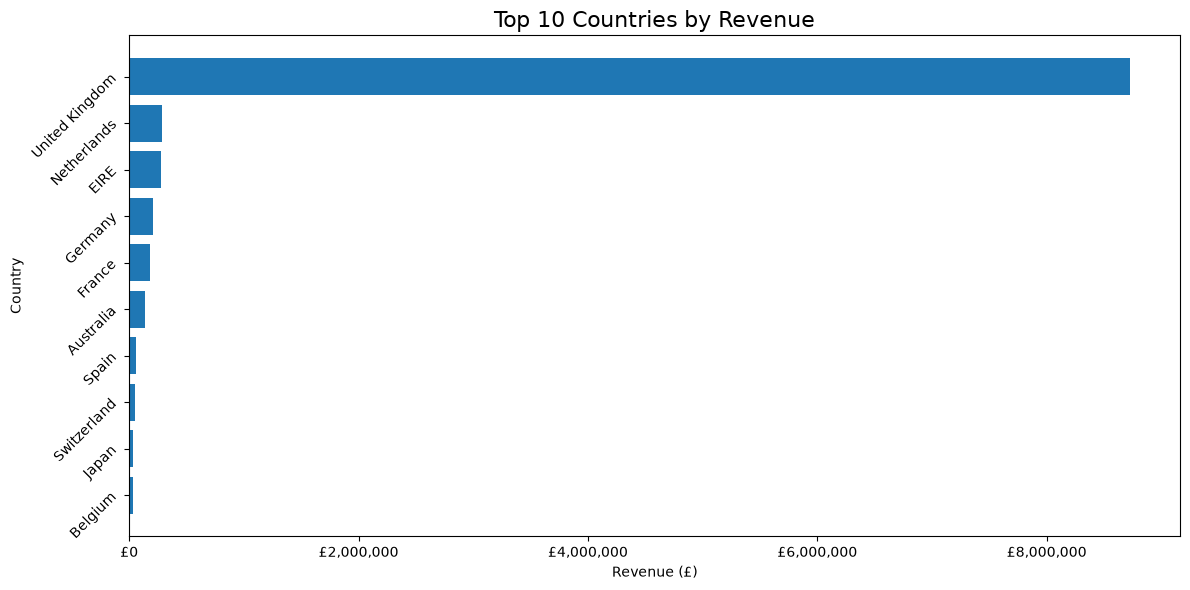

In [4]:
# 2. Visualize the top 10 countries by revenue using a horizontal bar chart
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_countries_revenue.index,
    top_10_countries_revenue.values
)

plt.title('Top 10 Countries by Revenue', fontsize=16)
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [5]:
# 3. Drop United Kingdom for now
non_uk_revenue = (
    product_sales[
        product_sales['Country'] != 'United Kingdom'
    ]
    .groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Non-UK Countries by Revenue:", non_uk_revenue.head(10))

Top 10 Non-UK Countries by Revenue: Country
Netherlands    283889.34
EIRE           276090.86
Germany        205381.15
France         184679.00
Australia      138103.81
Spain           55706.56
Switzerland     53065.60
Japan           37416.37
Belgium         36927.34
Sweden          36828.83
Name: Revenue, dtype: float64


In [6]:
top_10_non_uk_revenue = non_uk_revenue.head(10)

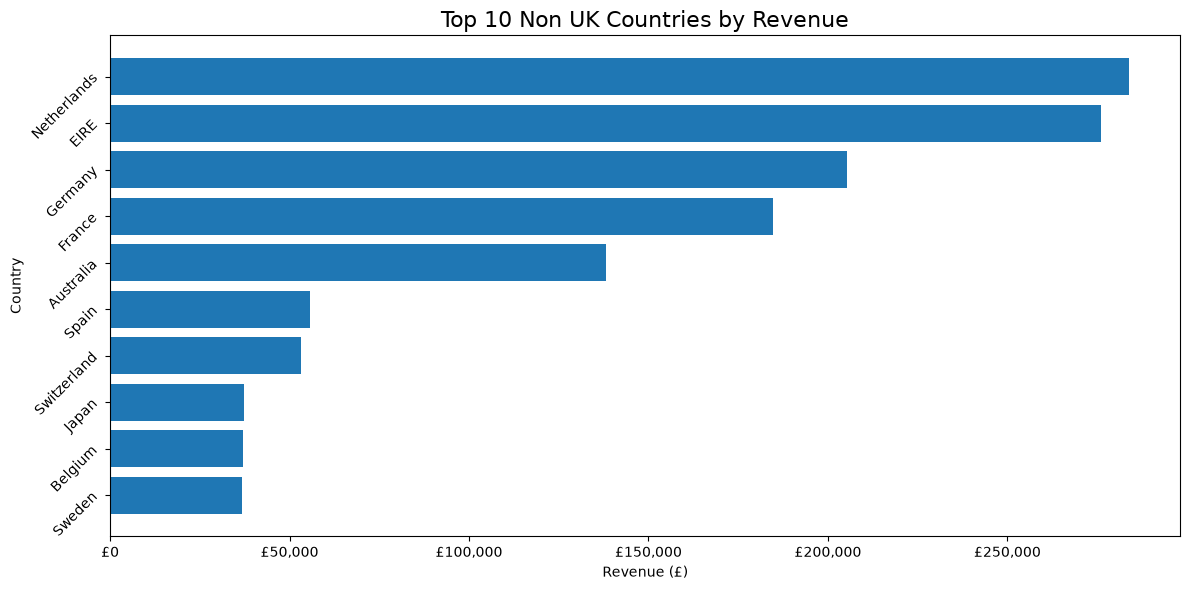

In [7]:
# 4. Visualize the top 10 non-UK countries by revenue using a vertical bar chart
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_non_uk_revenue.index,
    top_10_non_uk_revenue.values
)

plt.title('Top 10 Non UK Countries by Revenue', fontsize=16)
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [8]:
# 5. Top 10 countries by order count
top_countries_order_count = product_sales.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False)

print("Top 10 Countries by Order Count:", top_countries_order_count.head(10))

Top 10 Countries by Order Count: Country
United Kingdom    17912
Germany             443
France              383
EIRE                284
Belgium              98
Netherlands          93
Spain                88
Australia            56
Portugal             50
Switzerland          50
Name: InvoiceNo, dtype: int64


In [9]:
top_10_countries_order_count = top_countries_order_count.head(10)

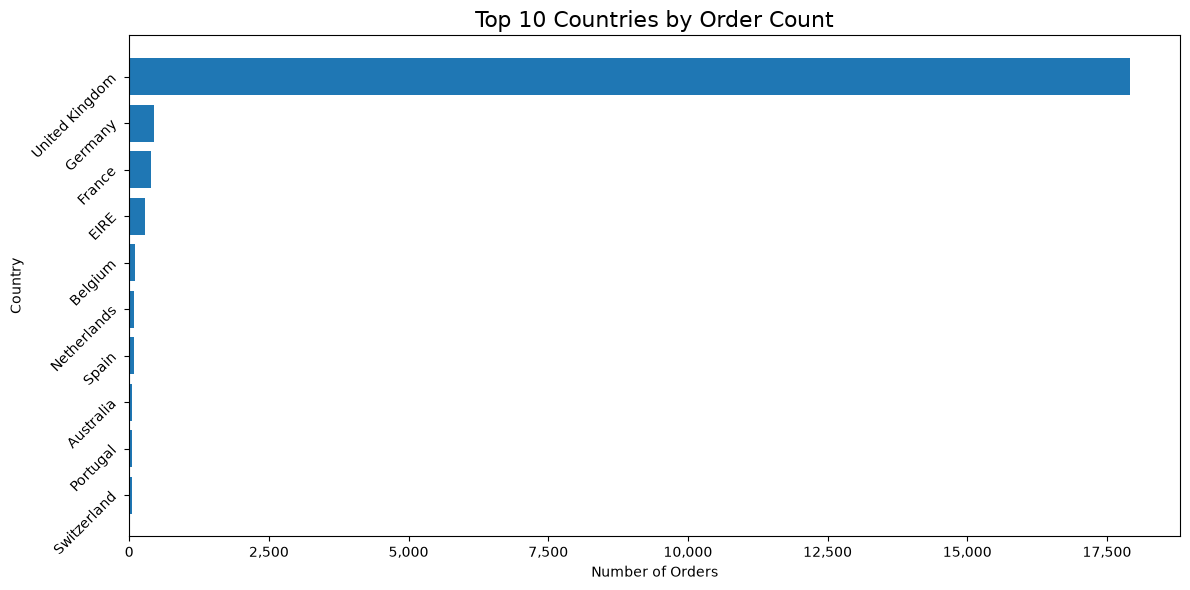

In [10]:
# 6. Visualize the top 10 countries by order count using a horizontal bar chart
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_countries_order_count.index,
    top_10_countries_order_count.values
)

plt.title('Top 10 Countries by Order Count', fontsize=16)
plt.xlabel('Number of Orders')
plt.ylabel('Country')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [11]:
# 7. Drop United Kingdom for order count analysis
non_uk_order_count = (
    product_sales[
        product_sales['Country'] != 'United Kingdom'
    ]
    .groupby('Country')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Non-UK Countries by Order Count:", non_uk_order_count.head(10))

Top 10 Non-UK Countries by Order Count: Country
Germany        443
France         383
EIRE           284
Belgium         98
Netherlands     93
Spain           88
Australia       56
Portugal        50
Switzerland     50
Finland         40
Name: InvoiceNo, dtype: int64


In [12]:
top_10_non_uk_order_count = non_uk_order_count.head(10)

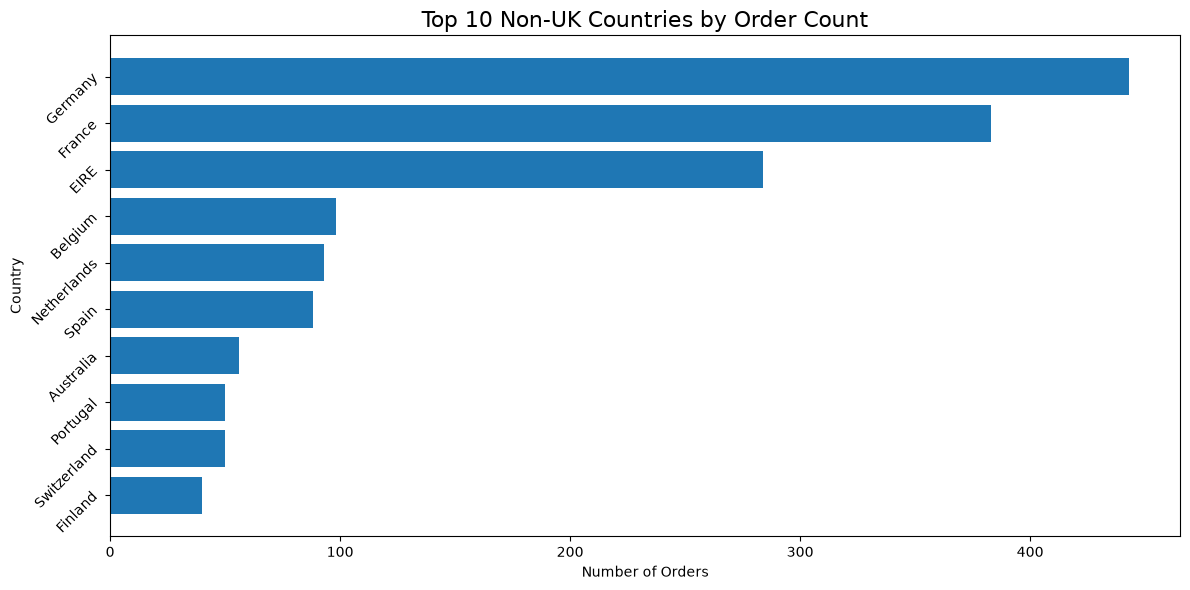

In [13]:
# 8. Visualize the top 10 non-UK countries by order count using a horizontal bar chart
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_non_uk_order_count.index,
    top_10_non_uk_order_count.values
)

plt.title('Top 10 Non-UK Countries by Order Count', fontsize=16)
plt.xlabel('Number of Orders')
plt.ylabel('Country')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [14]:
# 9. Top 10 countries by Quantity sold
top_countries_quantity_sold = product_sales.groupby('Country')['Quantity'].sum().sort_values(ascending=False)
print("Top 10 Countries by Quantity Sold:", top_countries_quantity_sold.head(10))

Top 10 Countries by Quantity Sold: Country
United Kingdom    4639155
Netherlands        200258
EIRE               147002
Germany            118032
France             111229
Australia           83890
Sweden              36037
Switzerland         30515
Spain               27724
Japan               26016
Name: Quantity, dtype: int64


In [15]:
top_10_countries_quantity_sold = top_countries_quantity_sold.head(10)

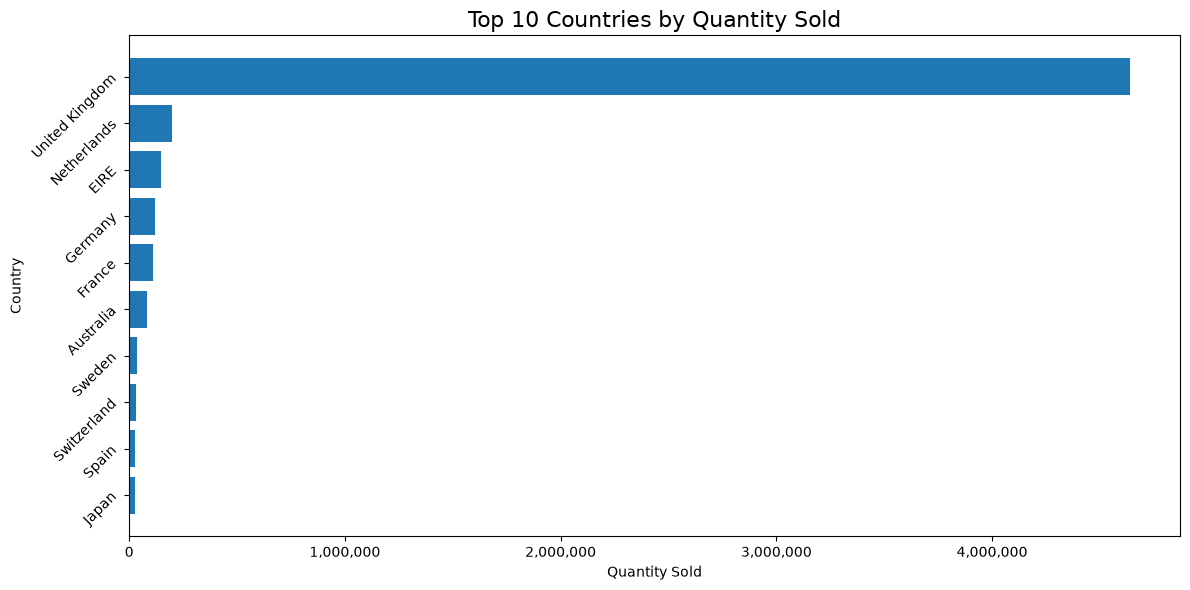

In [16]:
# 10. Visualize the top 10 countries by Quantity sold using a horizontal bar chart
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_countries_quantity_sold.index,
    top_10_countries_quantity_sold.values
)

plt.title('Top 10 Countries by Quantity Sold', fontsize=16)
plt.xlabel('Quantity Sold')
plt.ylabel('Country')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [17]:
# 11. Drop United Kingdom for Quantity sold analysis
non_uk_quantity_sold = (
    product_sales[
        product_sales['Country'] != 'United Kingdom'
    ]
    .groupby('Country')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Non-UK Countries by Quantity Sold:", non_uk_quantity_sold.head(10))

Top 10 Non-UK Countries by Quantity Sold: Country
Netherlands    200258
EIRE           147002
Germany        118032
France         111229
Australia       83890
Sweden          36037
Switzerland     30515
Spain           27724
Japan           26016
Belgium         22962
Name: Quantity, dtype: int64


In [18]:
top_10_non_uk_quantity_sold = non_uk_quantity_sold.head(10)

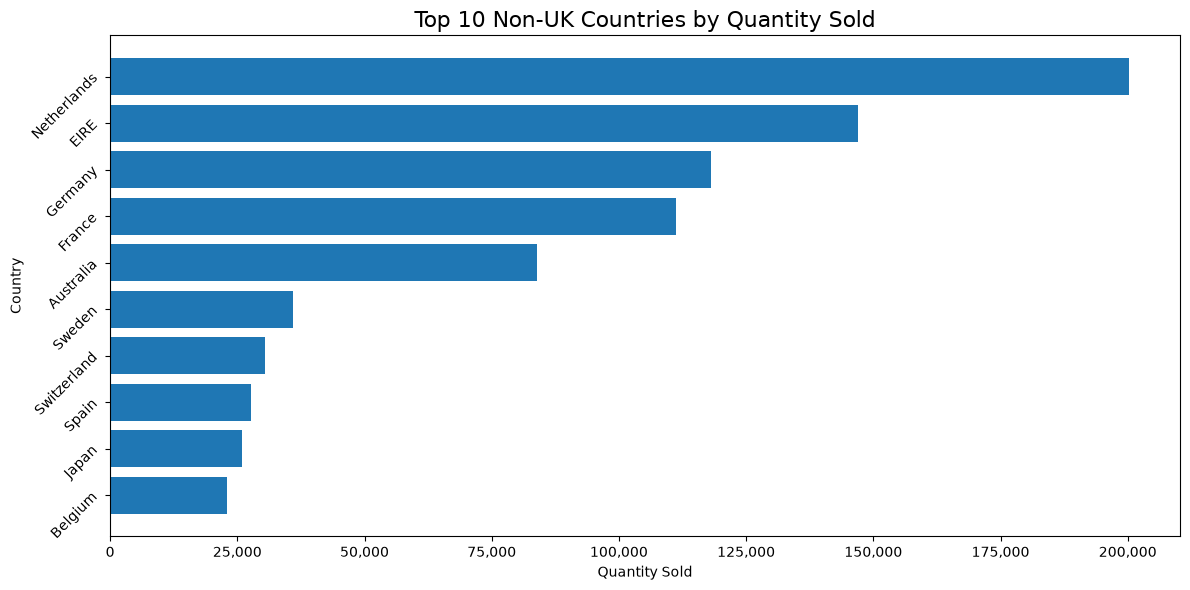

In [19]:
# 12. Visualize the top 10 non-UK countries by Quantity sold using a horizontal bar chart
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_non_uk_quantity_sold.index,
    top_10_non_uk_quantity_sold.values
)

plt.title('Top 10 Non-UK Countries by Quantity Sold', fontsize=16)
plt.xlabel('Quantity Sold')
plt.ylabel('Country')
plt.yticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [20]:
# Calculate the AOV for each country
aov_by_country = product_sales.groupby('Country').apply(lambda x: x['Revenue'].sum() / x['InvoiceNo'].nunique())

print("Top 10 Countries by Average Order Value (AOV):", aov_by_country.sort_values(ascending=False).head(10))

Top 10 Countries by Average Order Value (AOV): Country
Netherlands    3052.573548
Australia      2466.139464
Singapore      2280.097500
Japan          1969.282632
Lebanon        1693.880000
Hong Kong      1392.027143
Brazil         1143.600000
Sweden         1083.200882
Switzerland    1061.312000
Israel         1016.176250
dtype: float64


In [21]:
# 13. Best product sold in each country by total revenue
best_product_by_country = product_sales.groupby(['Country', 'Description'])['Revenue'].sum().reset_index()

print("Best Product Sold in Each Country by Total Revenue:\n", best_product_by_country.sort_values(['Country', 'Revenue'], ascending=[True, False]).groupby('Country').head(1))

Best Product Sold in Each Country by Total Revenue:
                     Country                          Description    Revenue
376               Australia                   RABBIT NIGHT LIGHT    3375.84
780                 Austria       PACK OF 6 PANNETONE GIFT BOXES     302.40
920                 Bahrain   OCEAN SCENT CANDLE IN JEWELLED BOX     231.24
1485                Belgium  ROUND SNACK BOXES SET OF4 WOODLAND     1181.40
1736                 Brazil             REGENCY CAKESTAND 3 TIER     175.20
1840                 Canada           RETRO COFFEE MUGS ASSORTED     534.24
2201        Channel Islands             REGENCY CAKESTAND 3 TIER     517.80
2686                 Cyprus   RUSTIC  SEVENTEEN DRAWER SIDEBOARD     580.00
2836         Czech Republic  ROUND SNACK BOXES SET OF4 WOODLAND       70.80
3006                Denmark                   RED KITCHEN SCALES     734.40
4521                   EIRE             REGENCY CAKESTAND 3 TIER    7793.25
5113     European Community        

In [22]:
# 14. Best product sold in each country by total quantity
best_product_by_country_quantity = product_sales.groupby(['Country', 'Description'])['Quantity'].sum().reset_index()

print("Best Product Sold in Each Country by Total Quantity:\n", best_product_by_country_quantity.sort_values(['Country', 'Quantity'], ascending=[True, False]).groupby('Country').head(1))

Best Product Sold in Each Country by Total Quantity:
                     Country                          Description  Quantity
287               Australia              MINI PAINT SET VINTAGE       2952
850                 Austria     SET 12 KIDS COLOUR  CHALK STICKS       288
917                 Bahrain           ICE CREAM SUNDAE LIP GLOSS        96
1343                Belgium      PACK OF 72 RETROSPOT CAKE CASES       480
1713                 Brazil                 DOLLY GIRL LUNCH BOX        24
1840                 Canada           RETRO COFFEE MUGS ASSORTED       504
2177        Channel Islands                         RAIN PONCHO        407
2519                 Cyprus       HEART DECORATION PAINTED ZINC        384
2842         Czech Republic   WOODEN STAR CHRISTMAS SCANDINAVIAN        72
3004                Denmark               RED  HARMONICA IN BOX        288
4272                   EIRE      PACK OF 72 RETROSPOT CAKE CASES      1800
5139     European Community       RED ROCKING 

In [23]:
# Compare all three metrics (Revenue, Order Count, Quantity Sold) between UK and non-UK countries and put it in a DataFrame for easy comparison
uk_data = product_sales[product_sales['Country'] == 'United Kingdom']
non_uk_data = product_sales[product_sales['Country'] != 'United Kingdom']

uk_summary = pd.Series({
    'total_revenue': uk_data['Revenue'].sum(),
    'order_count': uk_data['InvoiceNo'].nunique(),
    'total_quantity': uk_data['Quantity'].sum()
})

non_uk_summary = pd.Series({
    'total_revenue': non_uk_data['Revenue'].sum(),
    'order_count': non_uk_data['InvoiceNo'].nunique(),
    'total_quantity': non_uk_data['Quantity'].sum()
})

comparison_df = pd.DataFrame({
    'UK': uk_summary,
    'Non-UK': non_uk_summary
})

comparison_df.loc[['order_count', 'total_quantity']] = (
    comparison_df.loc[['order_count', 'total_quantity']].astype(int)
)

print("Comparison of UK and Non-UK Metrics:\n", comparison_df)

Comparison of UK and Non-UK Metrics:
                          UK      Non-UK
total_revenue   8726000.344  1528351.65
order_count       17912.000     1875.00
total_quantity  4639155.000   922385.00


# Summary

This notebook analyzes geographic sales performance using sales_data_deduped.csv, focusing on total revenue, quantity sold, and order count. The analysis revealed the following:
- United Kingdom: Recorded the highest total revenue (£8,726,000.34), quantity sold (4,639,155 units), and order count (17,912 orders).
- Outside the United Kingdom: The Netherlands recorded the highest total revenue (£283,889) and quantity sold (200,258 units), while Germany had the highest order count (443 orders).